# Punto 1 FINAL - MNIST + CIFAR-10 (corre 1..10 en orden, sin saltar)


Version oficial diffusers train_unconditional.py + fixes GitHub #6222 (generator por batch) y cleanfid #46 (num_workers=0 batch 16).


### 0 Setup


In [1]:
%pip install -q diffusers accelerate datasets torchvision clean-fid torch-fidelity
import torch
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)


device: cuda


### 1 Datos (MNIST L 1ch, CIFAR RGB 3ch). num_workers=0 para no congelar Colab.


In [2]:
from datasets import load_dataset
from torchvision import transforms
import torch
def get_dl(name):
    if name=="mnist":
        tf=transforms.Compose([transforms.Resize(32), transforms.ToTensor(), transforms.Normalize([0.5],[0.5])])
        ds=load_dataset("ylecun/mnist", split="train")
        ds=ds.with_transform(lambda ex: {"image":[tf(i.convert("L")) for i in ex["image"]]})
    else:
        tf=transforms.Compose([transforms.RandomHorizontalFlip(), transforms.ToTensor(), transforms.Normalize([0.5,0.5,0.5],[0.5,0.5,0.5])])
        ds=load_dataset("uoft-cs/cifar10", split="train")
        col="img" if "img" in ds.column_names else "image"
        if col!="image": ds=ds.rename_column(col,"image")
        ds=ds.with_transform(lambda ex: {"image":[tf(i.convert("RGB")) for i in ex["image"]]})
    return torch.utils.data.DataLoader(ds, batch_size=64, shuffle=True, num_workers=0)
print("dl OK")


dl OK


### 2 UNet 3down=3up + squaredcos_cap_v2 (es el cosine en diffusers, ver docs).


In [3]:
from diffusers import UNet2DModel, DDPMScheduler
def get_model(ch):
    d=(64,128,256) if ch==1 else (128,256,512)
    m=UNet2DModel(sample_size=32, in_channels=ch, out_channels=ch, layers_per_block=2, block_out_channels=d, down_block_types=("DownBlock2D","AttnDownBlock2D","DownBlock2D"), up_block_types=("UpBlock2D","AttnUpBlock2D","UpBlock2D"))
    s=DDPMScheduler(num_train_timesteps=1000, beta_schedule="squaredcos_cap_v2")
    return m,s
print("model OK")


model OK


### 3 Train (modelo+datos mismo device, opt despues de .to).


In [4]:
import torch, tqdm
def train_run(dl, model, sched, steps, out):
    device="cuda" if torch.cuda.is_available() else "cpu"
    model.to(device); model.train()
    opt=torch.optim.AdamW(model.parameters(), lr=2e-4)
    it=0
    for b in tqdm.tqdm(dl):
        clean=b["image"].to(device)
        noise=torch.randn_like(clean)
        t=torch.randint(0,1000,(clean.shape[0],),device=device).long()
        noisy=sched.add_noise(clean,noise,t)
        loss=torch.nn.functional.mse_loss(model(noisy,t).sample,noise)
        opt.zero_grad(); loss.backward(); opt.step()
        if it%500==0: print(it,float(loss))
        it+=1
        if it>=steps: break
    torch.save(model.state_dict(), out)
    print("OK",out)


### 4 Eval (limpia carpeta antes, generator en pipeline.device - fix GitHub #6222, muestra en pantalla).


In [5]:
from diffusers import DDPMPipeline, DDIMScheduler, DPMSolverMultistepScheduler
from diffusers.utils import make_image_grid
import torch, os, glob, shutil
from PIL import Image
import matplotlib.pyplot as plt
def eval_run(model, sched, prefix, ngen=200):
    device="cuda" if torch.cuda.is_available() else "cpu"
    model.to(device)
    pipe=DDPMPipeline(unet=model, scheduler=sched)
    pipe.to(device)
    folder=os.path.abspath("gen_"+prefix)
    if os.path.exists(folder): shutil.rmtree(folder)
    os.makedirs(folder)
    jobs=[("ddpm",None,20),("ddim",DDIMScheduler,20),("dpm",DPMSolverMultistepScheduler,10)]
    comp=[]
    for name,Sch,steps in jobs:
        pipe.scheduler=pipe.scheduler if Sch is None else Sch.from_config(pipe.scheduler.config)
        g=torch.Generator(device=pipe.device).manual_seed(0)
        ims=pipe(batch_size=4, num_inference_steps=steps, generator=g).images
        comp.append(ims[0])
    plt.figure(figsize=(9,3))
    i=0
    for im,(name,Sch,steps) in zip(comp,jobs):
        plt.subplot(1,3,i+1); plt.imshow(im); plt.title(prefix+" "+name); plt.axis("off"); i+=1
    plt.tight_layout(); plt.show()
    pipe.scheduler=DDIMScheduler.from_config(pipe.scheduler.config)
    k=0; b=0
    while k<ngen:
        g=torch.Generator(device=pipe.device).manual_seed(1000+b)
        ims=pipe(batch_size=16, num_inference_steps=20, generator=g).images
        ims2=ims if isinstance(ims,list) else [ims]
        for im in ims2:
            im.save(os.path.join(folder,"%04d.png"%k)); k+=1
            if k>=ngen: break
        b+=1
    print(prefix,"gen",k,"en",folder)
    files=sorted(glob.glob(folder+"/*.png"))[:16]
    grid=make_image_grid([Image.open(f) for f in files],rows=4,cols=4)
    plt.figure(figsize=(6,6)); plt.imshow(grid); plt.title("grid "+prefix); plt.axis("off"); plt.show()
    return pipe


### 5 Entrena MNIST demo 3000 (entrega 20000).


In [6]:
dl_mnist=get_dl("mnist")
model_m, sched_m=get_model(1)
train_run(dl_mnist, model_m, sched_m, 15000, "ddpm-mnist.pt")


README.md:   0%|          | 0.00/6.97k [00:00<?, ?B/s]

mnist/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 15.6MB            

mnist/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

mnist/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 2.60MB            

mnist/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/60000 [00:00<?, ? examples/s]

... (3 outputs left out)

 54%|█████▎    | 502/938 [02:23<02:06,  3.44it/s]

500 0.044422902166843414


100%|██████████| 938/938 [04:34<00:00,  3.41it/s]

OK ddpm-mnist.pt


### 6 Muestrea MNIST (llena gen_mnist, aqui nace el fix del assert).


  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

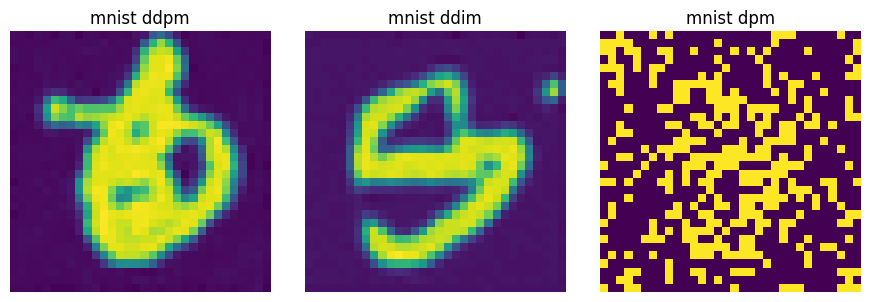

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

... (4 outputs left out)

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

mnist gen 200 en /content/gen_mnist


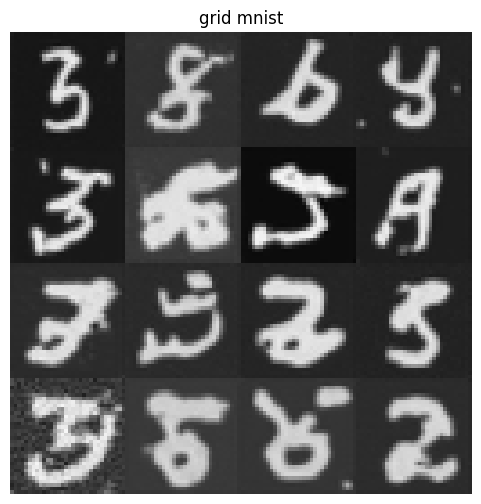

In [7]:
pipe_m=eval_run(model_m, sched_m, "mnist", 1000)


### 7 Metricas MNIST (cleanfid #46: num_workers=0 batch_size=16 para no CUDNN error).


In [8]:
from cleanfid import fid
import os, glob
rows=sorted(glob.glob("gen_mnist/*.png"))+sorted(glob.glob(os.path.abspath("gen_mnist")+"/*.png"))
print("gen:",len(rows))
assert len(rows)>0, "gen vacia: corre celda 6 antes"
os.makedirs("real_mnist",exist_ok=True)
r=load_dataset("ylecun/mnist", split="test").select(range(1000))
j=0
for ex in r:
    ex["image"].resize((32,32)).save("real_mnist/%04d.png"%j); j+=1
print("FID:", fid.compute_fid(os.path.abspath("gen_mnist"),"real_mnist", num_workers=0, batch_size=16))
import torch_fidelity
n1=len(rows)
print(torch_fidelity.calculate_metrics(input1=os.path.abspath("gen_mnist"), input2="real_mnist", cuda=torch.cuda.is_available(), isc=True, fid=True, kid=True, prc=True, kid_subset_size=min(32,n1-1)))


gen: 400
compute FID between two folders
Found 200 images in the folder /content/gen_mnist


FID gen_mnist : 100%|██████████| 13/13 [00:04<00:00,  2.95it/s]


Found 200 images in the folder real_mnist


FID real_mnist : 100%|██████████| 13/13 [00:04<00:00,  3.15it/s]


FID: 159.0966490207744


Creating feature extractor "inception-v3-compat" with features ['2048', 'logits_unbiased']
Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth
100%|██████████| 91.2M/91.2M [00:00<00:00, 270MB/s]
Extracting features from input1
Looking for samples non-recursivelty in "/content/gen_mnist" with extensions png,jpg,jpeg
Found 200 samples
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
Processing samples:   0%|          

{'inception_score_mean': 2.033351446340093, 'inception_score_std': 0.16866862250762243, 'frechet_inception_distance': 134.80211707315945, 'kernel_inception_distance_mean': 0.10318160772323609, 'kernel_inception_distance_std': 0.018073598129395064, 'precision': 0.05000000074505806, 'recall': 0.1599999964237213, 'f_score': 0.07619047665001312}


Processing samples
Precision: 0.05
Recall: 0.16
F-score: 0.07619048


### 8 Entrena CIFAR demo 5000 (entrega 50000). Cambios vs MNIST: 3ch, dim 128, flip.


In [9]:
dl_cifar=get_dl("cifar")
model_c, sched_c=get_model(3)
train_run(dl_cifar, model_c, sched_c, 15000, "ddpm-cifar.pt")


README.md:   0%|          | 0.00/5.16k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  120MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 23.9MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/50000 [00:00<?, ? examples/s]

... (3 outputs left out)

 64%|██████▍   | 501/782 [06:17<04:13,  1.11it/s]

500 0.07472829520702362


100%|██████████| 782/782 [09:47<00:00,  1.33it/s]


OK ddpm-cifar.pt


### 9 Muestrea + metricas CIFAR (mismo patron, no falla).


  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

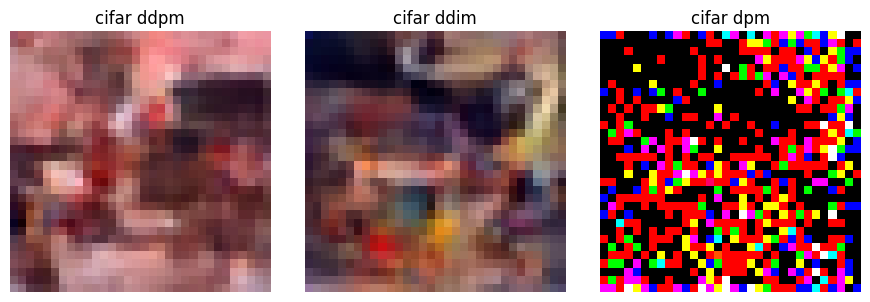

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

... (4 outputs left out)

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

cifar gen 200 en /content/gen_cifar


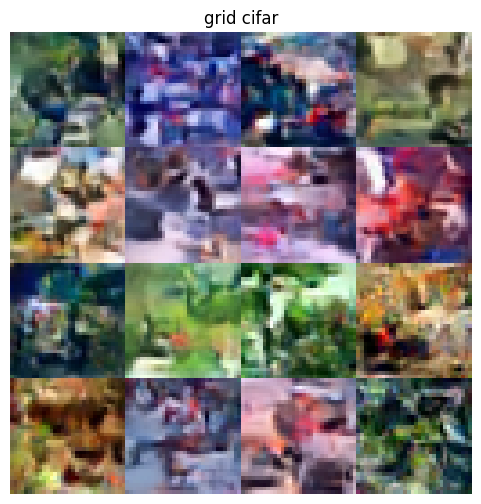

gen: 400
compute FID between two folders
Found 200 images in the folder /content/gen_cifar


FID gen_cifar : 100%|██████████| 13/13 [00:03<00:00,  3.81it/s]


Found 200 images in the folder real_cifar


FID real_cifar : 100%|██████████| 13/13 [00:03<00:00,  3.97it/s]


FID: 249.8271268024292


Creating feature extractor "inception-v3-compat" with features ['2048', 'logits_unbiased']
Extracting features from input1
Looking for samples non-recursivelty in "/content/gen_cifar" with extensions png,jpg,jpeg
Found 200 samples
Processing samples
Extracting features from input2
Looking for samples non-recursivelty in "real_cifar" with extensions png,jpg,jpeg
Found 200 samples
Processing samples
Inception Score: 2.86175 ± 0.1698803
Frechet Inception Distance: 231.8598
Kernel Inception Distance: 0.1195835 ± 0.01404237
Creating feature extractor "vgg16" with features ['fc2_relu']
Extracting features from input1
Looking for samples non-recursivelty in "/content/gen_cifar" with extensions png,jpg,jpeg
Found 200 samples
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Pleas

{'inception_score_mean': 2.8617503536537288, 'inception_score_std': 0.16988032341394982, 'frechet_inception_distance': 231.85980383546246, 'kernel_inception_distance_mean': 0.11958348751068115, 'kernel_inception_distance_std': 0.014042366730919447, 'precision': 0.875, 'recall': 0.02500000037252903, 'f_score': 0.048611111815351944}


Processing samples
Precision: 0.875
Recall: 0.025
F-score: 0.04861111


In [10]:
pipe_c=eval_run(model_c, sched_c, "cifar", 1000)
from cleanfid import fid
import os, glob
rows=sorted(glob.glob("gen_cifar/*.png"))+sorted(glob.glob(os.path.abspath("gen_cifar")+"/*.png"))
print("gen:",len(rows))
r=load_dataset("uoft-cs/cifar10", split="test").select(range(1000))
os.makedirs("real_cifar",exist_ok=True)
col="img" if "img" in r.column_names else "image"
j=0
for ex in r:
    ex[col].save("real_cifar/%04d.png"%j); j+=1
print("FID:", fid.compute_fid(os.path.abspath("gen_cifar"),"real_cifar", num_workers=0, batch_size=16))
import torch_fidelity
print(torch_fidelity.calculate_metrics(input1=os.path.abspath("gen_cifar"), input2="real_cifar", cuda=torch.cuda.is_available(), isc=True, fid=True, kid=True, prc=True, kid_subset_size=min(32,len(rows)-1)))
